In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sns.set_theme(style='whitegrid')
# plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
df = pd.read_csv('sales_data.csv')
df.head()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
0,TXN10000,2023-01-01 00:00:00,Clothing,8,500,5,Cash,South,4,4000,3800.0
1,TXN10001,2023-01-01 01:00:00,Beauty,3,300,10,Credit Card,West,5,900,810.0
2,TXN10002,2023-01-01 02:00:00,Home & Kitchen,8,300,5,UPI,East,3,2400,2280.0
3,TXN10003,2023-01-01 03:00:00,Home & Kitchen,5,500,5,Credit Card,East,4,2500,2375.0
4,TXN10004,2023-01-01 04:00:00,Electronics,1,150,20,Credit Card,East,4,150,120.0


In [3]:
df.tail()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
995,TXN10995,2023-02-11 11:00:00,Electronics,1,500,10,Cash,South,5,500,450.0
996,TXN10996,2023-02-11 12:00:00,Beauty,5,150,10,UPI,South,4,750,675.0
997,TXN10997,2023-02-11 13:00:00,Electronics,3,1200,0,Cash,North,4,3600,3600.0
998,TXN10998,2023-02-11 14:00:00,Beauty,1,12000,20,UPI,Central,5,12000,9600.0
999,TXN10999,2023-02-11 15:00:00,Clothing,4,2500,0,Net Banking,South,4,10000,10000.0


In [4]:
print('Rows and columns:', df.shape)


Rows and columns: (1000, 11)


In [5]:
print('\nColumn names:')
print(df.columns.tolist())


Column names:
['Transaction_ID', 'Date', 'Department', 'Units_Sold', 'Unit_Price', 'Discount_Percent', 'Payment_Method', 'Region', 'Customer_Rating', 'Total_Amount', 'Final_Amount']


In [79]:
df.info()  #numeric statistics.

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    1000 non-null   str    
 1   Date              1000 non-null   str    
 2   Department        1000 non-null   str    
 3   Units_Sold        1000 non-null   int64  
 4   Unit_Price        1000 non-null   int64  
 5   Discount_Percent  1000 non-null   int64  
 6   Payment_Method    985 non-null    str    
 7   Region            1000 non-null   str    
 8   Customer_Rating   1000 non-null   int64  
 9   Total_Amount      1000 non-null   int64  
 10  Final_Amount      1000 non-null   float64
dtypes: float64(1), int64(5), str(5)
memory usage: 86.1 KB


In [6]:
# Count missing values in each column
df.isnull().sum()

Transaction_ID       0
Date                 0
Department           0
Units_Sold           0
Unit_Price           0
Discount_Percent     0
Payment_Method      15
Region               0
Customer_Rating      0
Total_Amount         0
Final_Amount         0
dtype: int64

In [7]:
# Count duplicate rows
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


In [8]:
# Show rows where Payment_Method is missing
df[df['Payment_Method'].isnull()].head()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
76,TXN10076,2023-01-04 04:00:00,Books,9,5000,0,NaN,West,3,45000,45000.0
136,TXN10136,2023-01-06 16:00:00,Clothing,2,2500,5,NaN,North,5,5000,4750.0
411,TXN10411,2023-01-18 03:00:00,Beauty,9,1200,10,NaN,Central,3,10800,9720.0
513,TXN10513,2023-01-22 09:00:00,Books,9,2500,5,NaN,North,4,22500,21375.0
521,TXN10521,2023-01-22 17:00:00,Clothing,2,150,0,NaN,Central,3,300,300.0


In [9]:
# Handle missing payment methods
df['Payment_Method'] = df['Payment_Method'].fillna('Unknown')
print('Missing values after handling:')
print(df.isnull().sum())

Missing values after handling:
Transaction_ID      0
Date                0
Department          0
Units_Sold          0
Unit_Price          0
Discount_Percent    0
Payment_Method      0
Region              0
Customer_Rating     0
Total_Amount        0
Final_Amount        0
dtype: int64


In [10]:
# Prepare date column
df['Date'] = pd.to_datetime(df['Date'])

In [11]:
print("Data type:", df['Date'].dtype)
print(df['Date'].head())

Data type: datetime64[us]
0   2023-01-01 00:00:00
1   2023-01-01 01:00:00
2   2023-01-01 02:00:00
3   2023-01-01 03:00:00
4   2023-01-01 04:00:00
Name: Date, dtype: datetime64[us]


In [12]:
# Date range check karna
print('Date range:', df['Date'].min(), 'to', df['Date'].max())

Date range: 2023-01-01 00:00:00 to 2023-02-11 15:00:00


In [13]:
# Month column banana
df['Month'] = df['Date'].dt.to_period('M').astype(str)
# .dt dates par operations karne ke liye use hota hai.
#to_period('M') date ko year-month period mein convert karta hai.
# Ye period values ko string yani text mein convert karta hai.

In [14]:
df[['Date', 'Month']].head()

,Date,Month
0,2023-01-01 00:00:00,2023-01
1,2023-01-01 01:00:00,2023-01
2,2023-01-01 02:00:00,2023-01
3,2023-01-01 03:00:00,2023-01
4,2023-01-01 04:00:00,2023-01


In [15]:
# January ki sabhi dates ka month 2023-01 aur February ki dates ka 2023-02 ho jayega.

In [16]:
# Key Summary Numbers (Important Summary Numbers)



In [14]:
print('Number of transactions:', len(df))

Number of transactions: 1000


In [15]:
# Total units sold
print('Total units sold:', df['Units_Sold'].sum())

Total units sold: 4986


In [22]:
# Sales before discount
print('Sales before discount: ₹{:,.2f}'.format(df['Total_Amount'].sum())) #ctrl +alt +4



Sales before discount: ₹14,637,250.00


In [23]:
# Sales after discount
print('Sales after discount:  ₹{:,.2f}'.format(df['Final_Amount'].sum()))

Sales after discount:  ₹15,333,617.50


In [21]:
# Difference: Total_Amount discount se pehle ki amount hai, jabki Final_Amount discount ke baad ki amount hai.

In [24]:
# Average final amount per transaction
print('Average final amount per transaction: ₹{:,.2f}'.format(df['Final_Amount'].mean()))

Average final amount per transaction: ₹15,333.62


In [25]:
# Isse pata chalta hai ki ek transaction mein average kitni sales amount generate hui.

In [26]:
# Average customer rating
print('Average customer rating:', round(df['Customer_Rating'].mean(), 2))


Average customer rating: 3.69


In [27]:
# .mean() sabhi customer ratings ka average nikalta hai.
# round(..., 2) result ko decimal ke baad 2 digits tak round karta hai.
# Agar ratings 4, 5, 3, 4 hain, toh average rating 4.0 hogi.

In [29]:
## 7. Department-wise sales
#Compare sales after discount by department.

Department
Clothing          4218552.5
Electronics       4170150.0
Home & Kitchen    3515595.0
Books             2051957.5
Beauty            1377362.5
Name: Final_Amount, dtype: float64

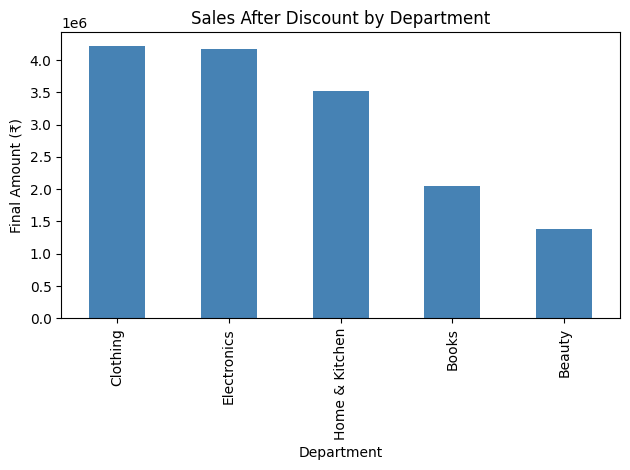

In [31]:
department_sales = df.groupby('Department')['Final_Amount'].sum().sort_values(ascending=False)
display(department_sales)

department_sales.plot(kind='bar', color='steelblue') #parameter
plt.title('Sales After Discount by Department')
plt.xlabel('Department')
plt.ylabel('Final Amount (₹)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()  #Graph ka layout adjust karna
plt.show()

In [30]:
# Transactions by region

Region
South      227
North      203
Central    198
East       188
West       184
Name: count, dtype: int64

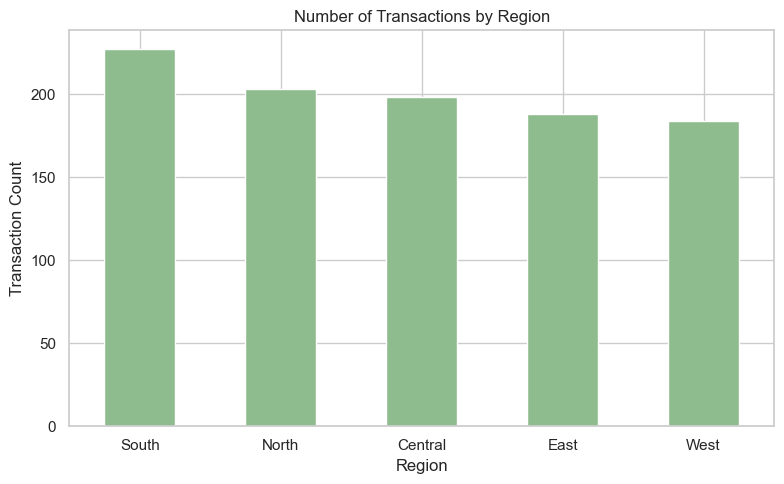

In [31]:
region_counts = df['Region'].value_counts()
display(region_counts)

region_counts.plot(kind='bar', color='darkseagreen')
plt.title('Number of Transactions by Region')
plt.xlabel('Region')
plt.ylabel('Transaction Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
# "Is graph mein hum transactions count kar rahe hain, sales amount nahi. Isliye humein pata chalta hai ki kis region mein kitni purchases hui hain, lekin kis region se sabse zyada revenue aaya, ye pata nahi chalta."

Payment_Method
Net Banking    217
Cash           198
UPI            196
Debit Card     188
Credit Card    186
Unknown         15
Name: count, dtype: int64

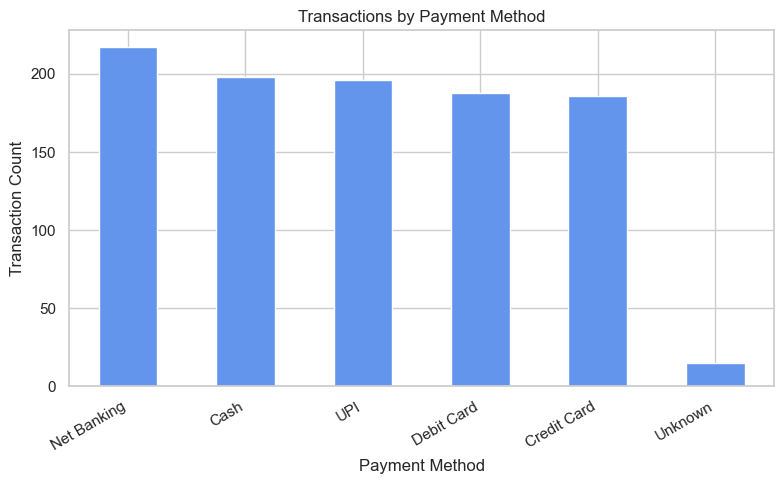

In [33]:
# Payment method analysis (transactions ki count dikhata)
payment_counts = df['Payment_Method'].value_counts()
display(payment_counts)

payment_counts.plot(kind='bar', color='cornflowerblue')
plt.title('Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Transaction Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Discount_Percent
0     399
5     185
10    220
15    100
20     96
Name: count, dtype: int64

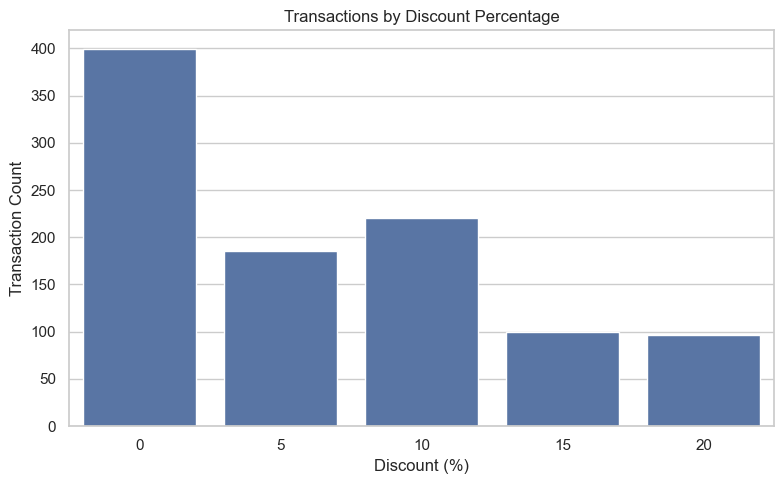

In [34]:
#  Discount analysis
# Dekho ki har alag discount percentage kitni baar use hua hai.

discount_counts = df['Discount_Percent'].value_counts().sort_index()
display(discount_counts)

sns.countplot(data=df, x='Discount_Percent')
plt.title('Transactions by Discount Percentage')
plt.xlabel('Discount (%)')
plt.ylabel('Transaction Count')
plt.tight_layout()
plt.show()

In [35]:
# 0% discount — 399 transactions: 399 transactions par koi discount nahi tha.
# 5% discount — 185 transactions: 185 transactions par 5% discount tha.
# 10% discount — 220 transactions: 220 transactions par 10% discount tha.
# 15% discount — 100 transactions: 100 transactions par 15% discount tha.
# 20% discount — 96 transactions: 96 transactions par 20% discount tha.

# Sabse zyada transactions: 0% discount par hui hain — 399 transactions.
# Sabse kam transactions: 20% discount par hui hain — 96 transactions.
# 10% discount: Is category mein 220 transactions hui hain, jo 5%, 15% aur 20% discount categories se zyada hain.

Customer_Rating
1     56
2    113
3    212
4    327
5    292
Name: count, dtype: int64

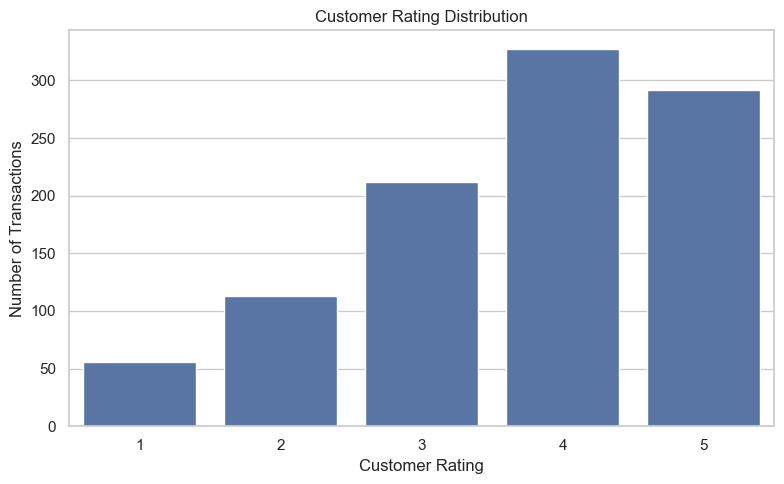

In [36]:
# Customer ratings
rating_counts = df['Customer_Rating'].value_counts().sort_index()
display(rating_counts)

sns.countplot(data=df, x='Customer_Rating')
plt.title('Customer Rating Distribution')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Transactions')
plt.tight_layout() #graph ki spacing adjust karta hai.
plt.show()

In [37]:
# Monthly sales trend

Month
2023-01    12113307.5
2023-02     3220310.0
Name: Final_Amount, dtype: float64

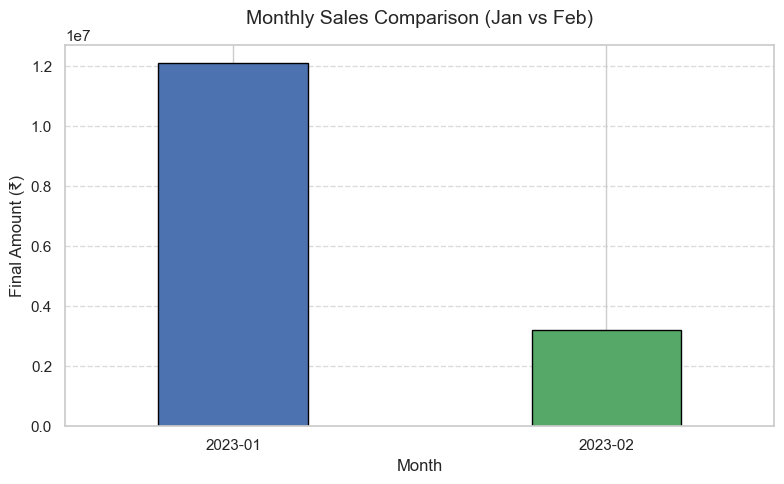

In [50]:
monthly_sales = df.groupby('Month')['Final_Amount'].sum()
display(monthly_sales)

# Figure size set karein
plt.figure(figsize=(8, 5))

# Bar chart plot karein with custom colors
monthly_sales.plot(
    kind='bar', color=['#4C72B0', '#55A868'], width=0.4, edgecolor='black'
)

# Title aur Labels
plt.title('Monthly Sales Comparison (Jan vs Feb)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Final Amount (₹)', fontsize=12)

# X-axis ke labels ko seedha rakhne ke liye
plt.xticks(rotation=0)

# Grid lines on y-axis for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Layout adjust karein aur show karein
plt.tight_layout()
plt.show()

In [43]:
# “Line chart ka use time ke saath sales ka trend dekhne ke liye karte hain, jabki bar chart ka use alag-alag months ki sales compare karne ke liye karte hain.”

In [52]:
print(df['Month'].unique())
print("Total months:", df['Month'].nunique())

<StringArray>
['2023-01', '2023-02']
Length: 2, dtype: str
Total months: 2


In [47]:
df['Month'].unique()

<StringArray>
['2023-01', '2023-02']
Length: 2, dtype: str

In [54]:
# Simple findings generated from the data

top_department = department_sales.idxmax()
top_region_by_transactions = region_counts.idxmax()
top_payment_method = payment_counts.idxmax()

print(f'Highest sales department: {top_department} (₹{department_sales.max():,.2f})')
print(f'Most transactions by region: {top_region_by_transactions} ({region_counts.max()} transactions)')
print(f'Most common payment method: {top_payment_method} ({payment_counts.max()} transactions)')
print(f'Average customer rating: {df["Customer_Rating"].mean():.2f} out of 5')

Highest sales department: Clothing (₹4,218,552.50)
Most transactions by region: South (227 transactions)
Most common payment method: Net Banking (217 transactions)
Average customer rating: 3.69 out of 5
